Autorzy: Brojek


1. Utworzyć korpus dokumentów na podstawie 5-10 książek pobranych ze strony Wolne Lektury: https://wolnelektury.pl/

In [17]:
from collections import Counter
from multiprocessing.reduction import duplicate

import matplotlib.pyplot as plt
import wordcloud


links = [
    "https://wolnelektury.pl/media/book/txt/quo-vadis.txt",             # Quo vadis
    "https://wolnelektury.pl/media/book/txt/pan-tadeusz.txt",           # Pan Tadeusz
    "https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt",     # Lalka - Tom I
    "https://wolnelektury.pl/media/book/txt/krzyzacy-tom-drugi.txt",    # Krzyżacy - Tom II
    "https://wolnelektury.pl/media/book/txt/wesele.txt",                # Wesele
    "https://wolnelektury.pl/media/book/txt/kordian.txt",               # Kordian
    "https://wolnelektury.pl/media/book/txt/balladyna.txt"              # Balladyna
]
corpus=[]

import requests
from bs4 import BeautifulSoup
requests.encoding = "utf-8"
for link in links:
    print(link)
    response=requests.get(link)
    decoded_text = response.content.decode('utf-8')
    print(response.status_code)
    response.encoding='utf-8'
    corpus.append(BeautifulSoup(decoded_text,'html.parser').get_text())
    #print(corpus[-1][:200])
# add up to 10 more and save it in list.
# download it with https://docs.python-requests.org/en/latest/

#expected outocme
#corpus  = [' Thisis the content of the first book',
#           'thisis the conent of the second book',
#           'thisis the conent of the third book' ]


https://wolnelektury.pl/media/book/txt/quo-vadis.txt
200
https://wolnelektury.pl/media/book/txt/pan-tadeusz.txt
200
https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt
200
https://wolnelektury.pl/media/book/txt/krzyzacy-tom-drugi.txt
200
https://wolnelektury.pl/media/book/txt/wesele.txt
200
https://wolnelektury.pl/media/book/txt/kordian.txt
200
https://wolnelektury.pl/media/book/txt/balladyna.txt
200


2. Dla każdej z pozycji zwizualizować:

a) częstość występowania klas gramatycznych

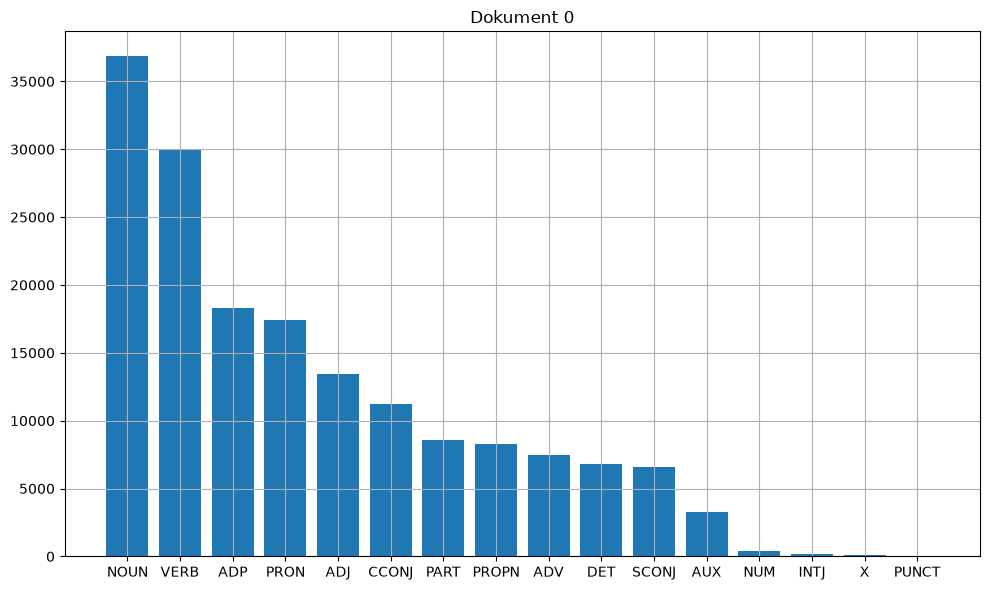

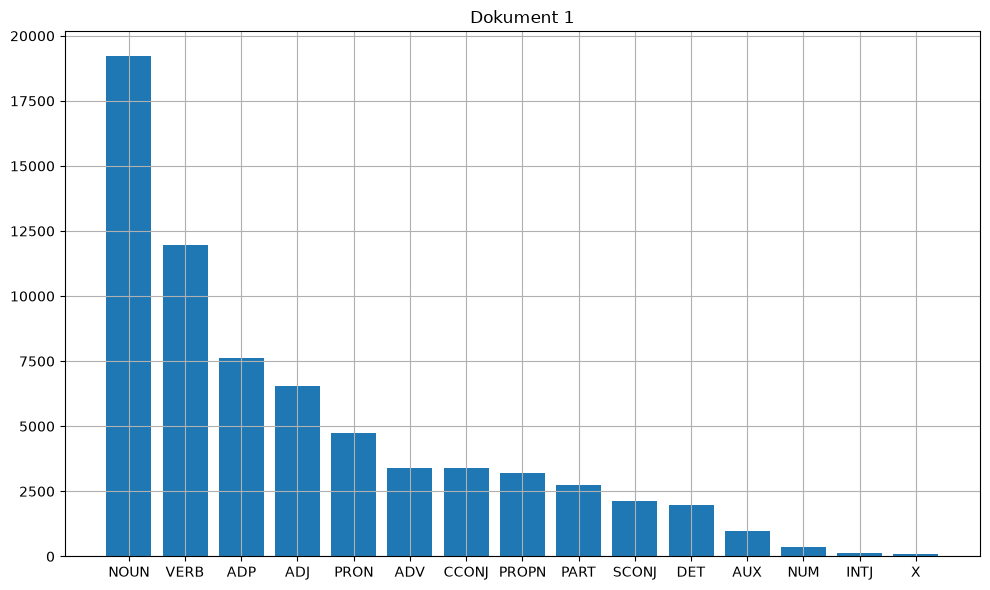

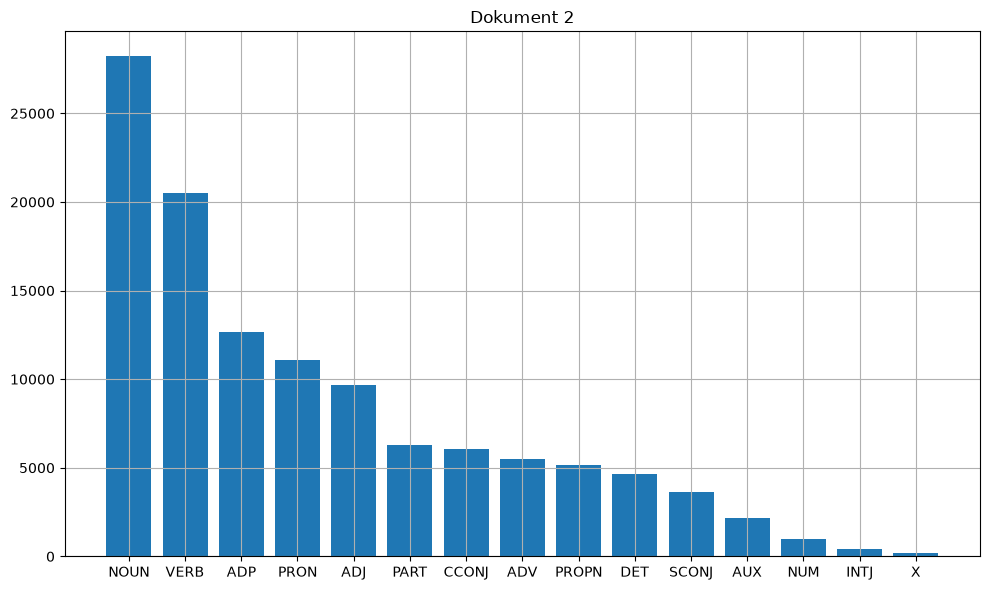

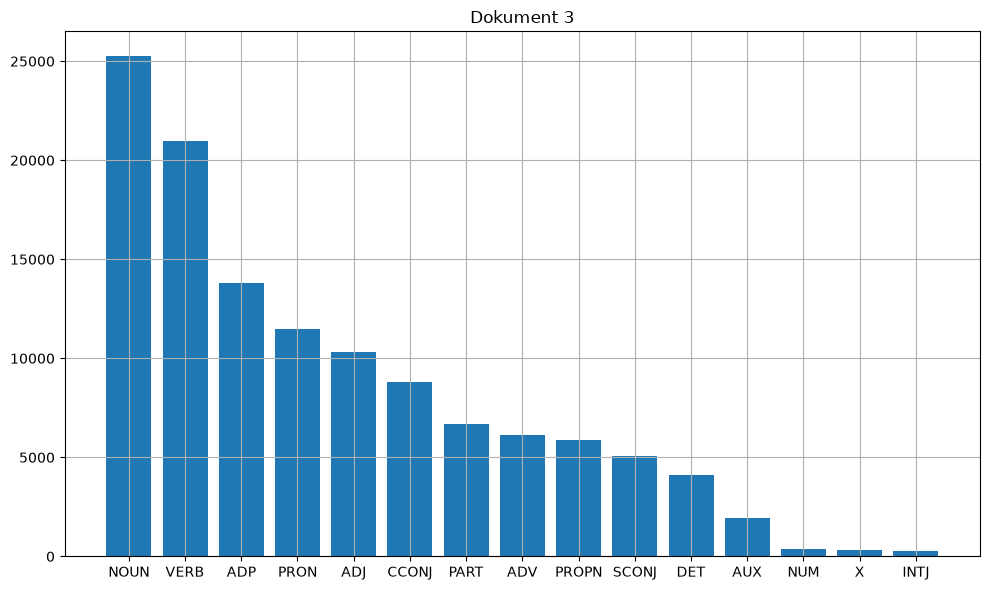

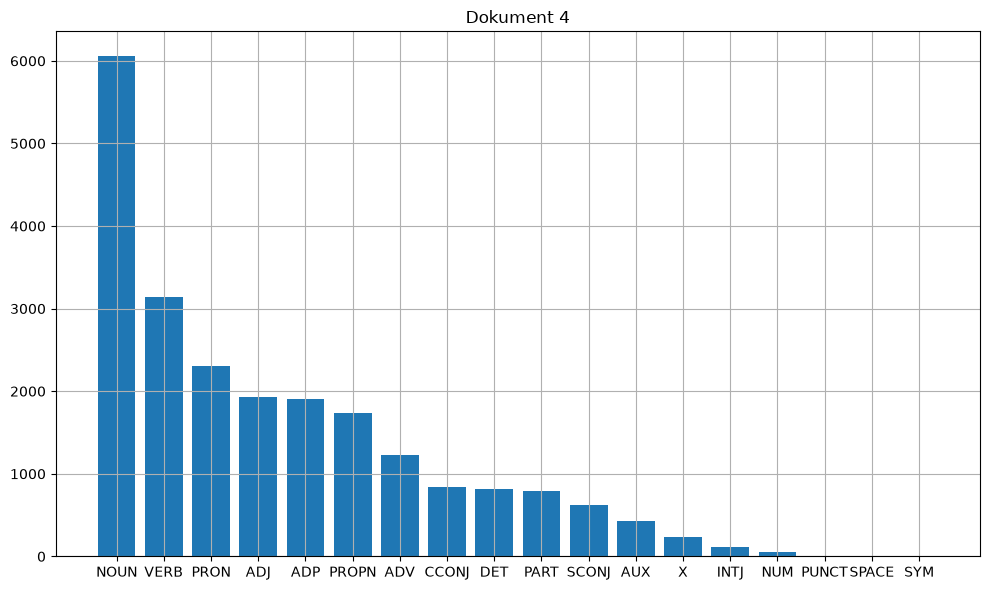

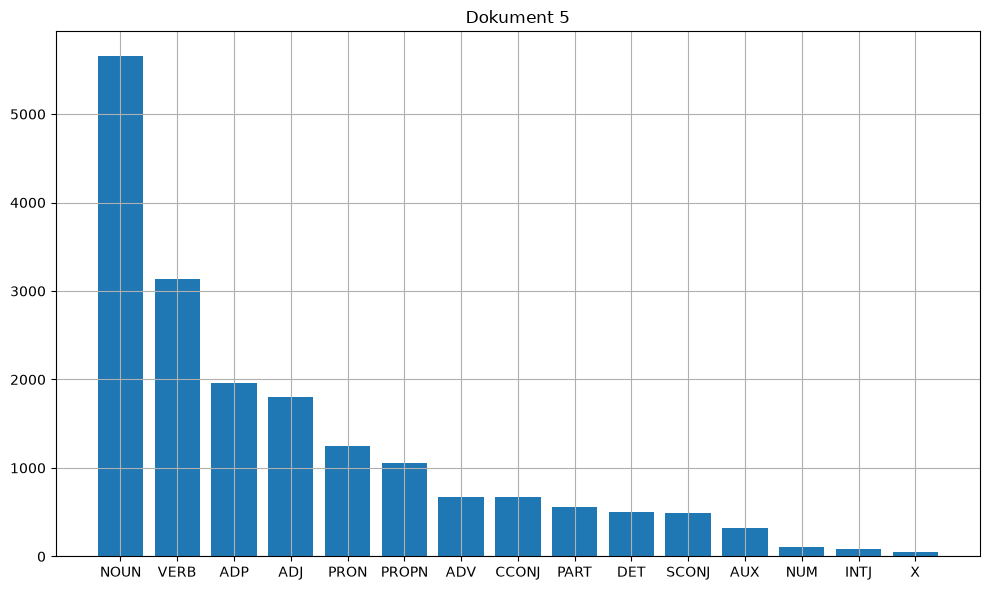

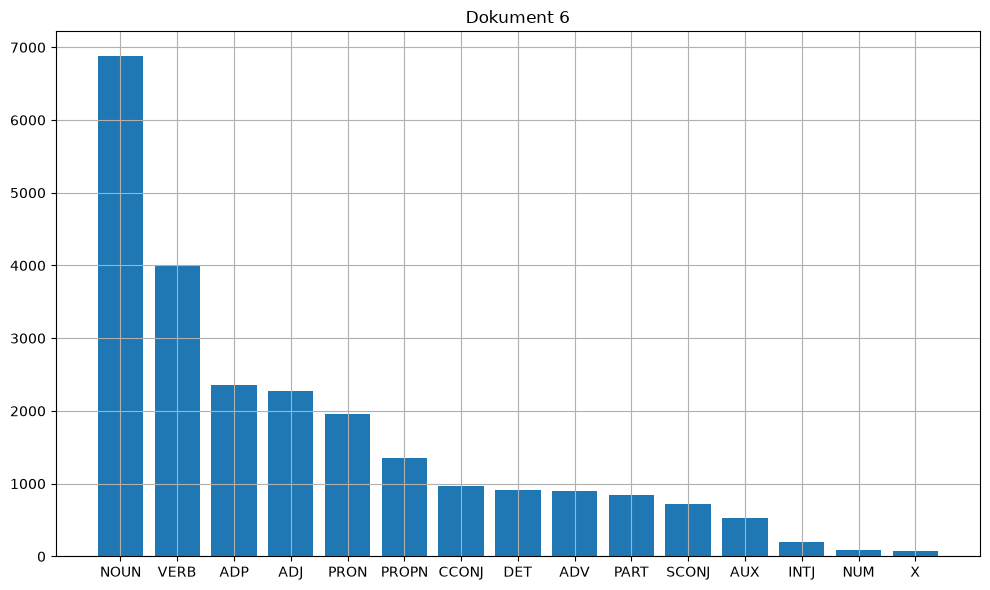

In [18]:
import spacy
from collections import Counter
import matplotlib.pyplot as plt
nlp = spacy.load("pl_core_news_sm")
nlp.max_length = 10000000
processed_books=[]

for i, book in enumerate(corpus):
    with nlp.disable_pipes("parser", "ner"):
        if "sentencizer" not in nlp.pipe_names:
            nlp.add_pipe("sentencizer")
        doc=nlp(book)
        processed_books.append(doc)
    pos_counts=Counter([token.pos_ for token in doc if not token.is_punct and not token.is_space])
    pos_counts = dict(pos_counts.most_common())

    plt.figure(figsize=(10, 6))
    plt.bar(pos_counts.keys(),pos_counts.values())
    plt.title(f'Dokument {i}')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

b) częstość występowania części mowy

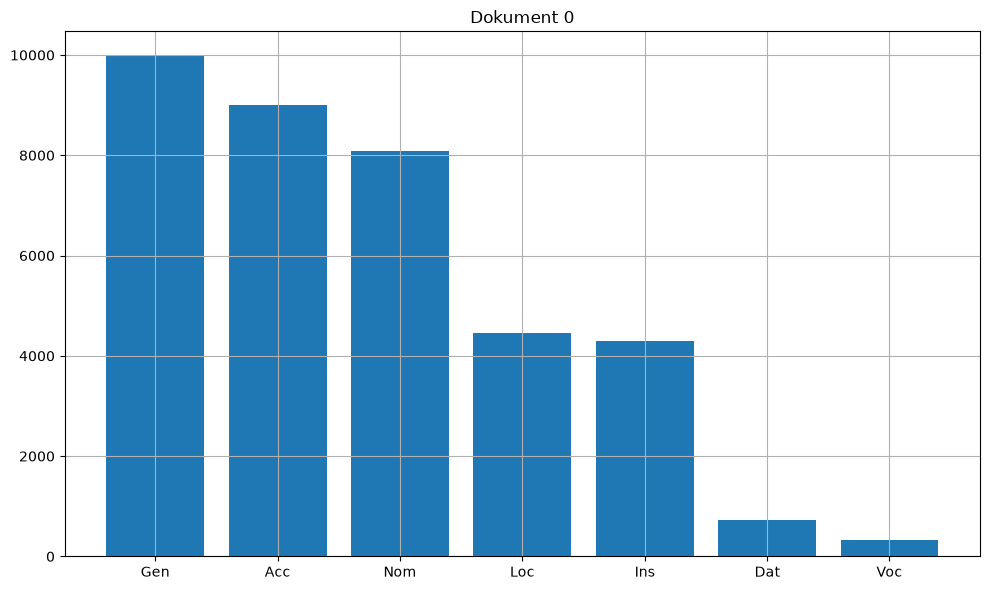

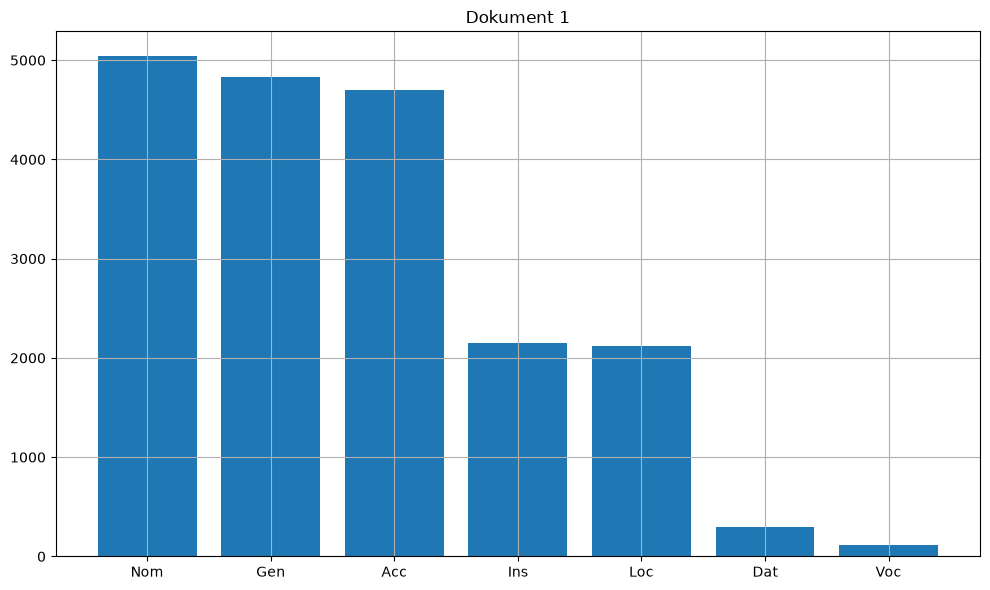

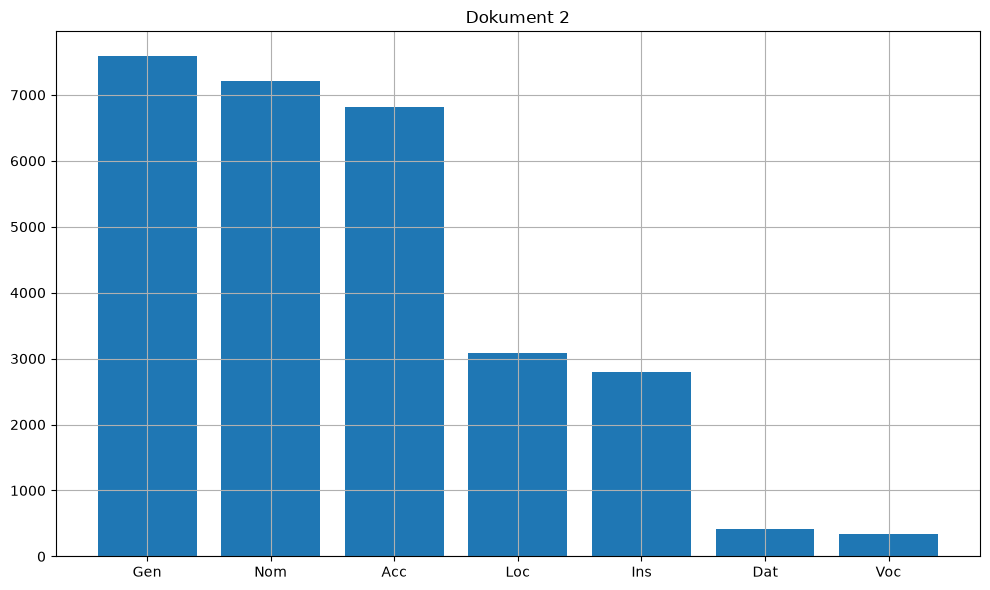

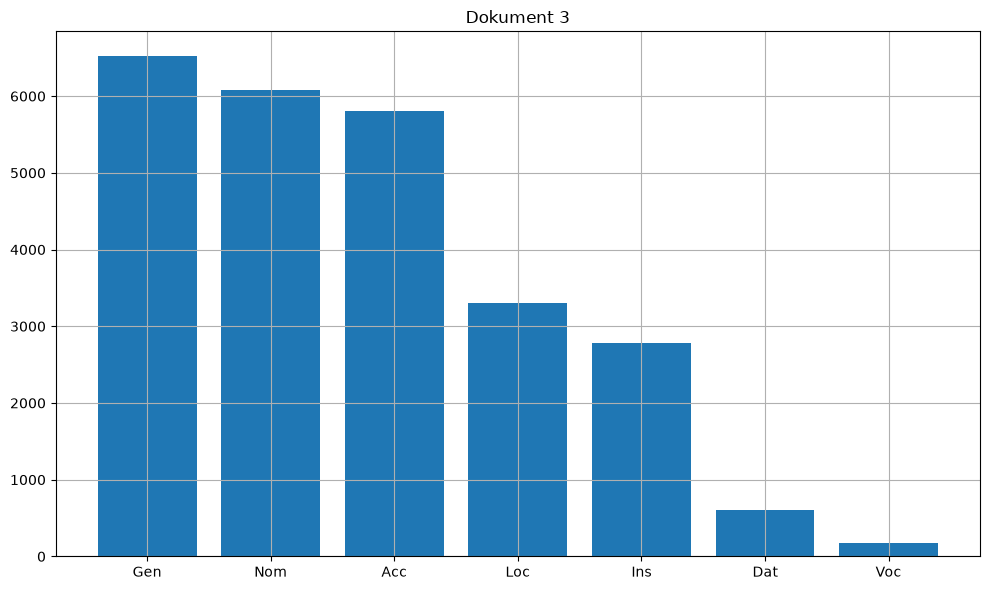

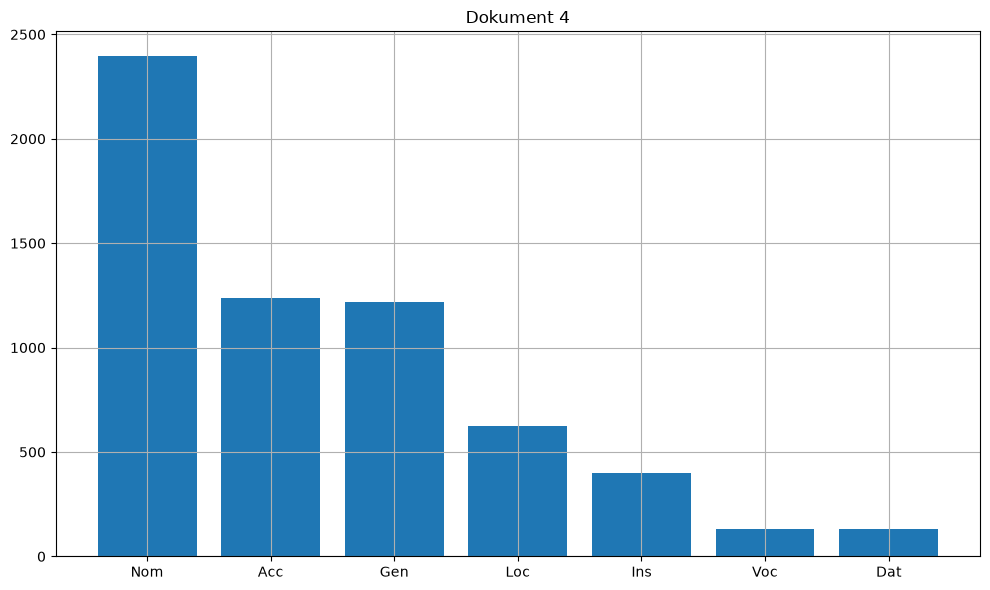

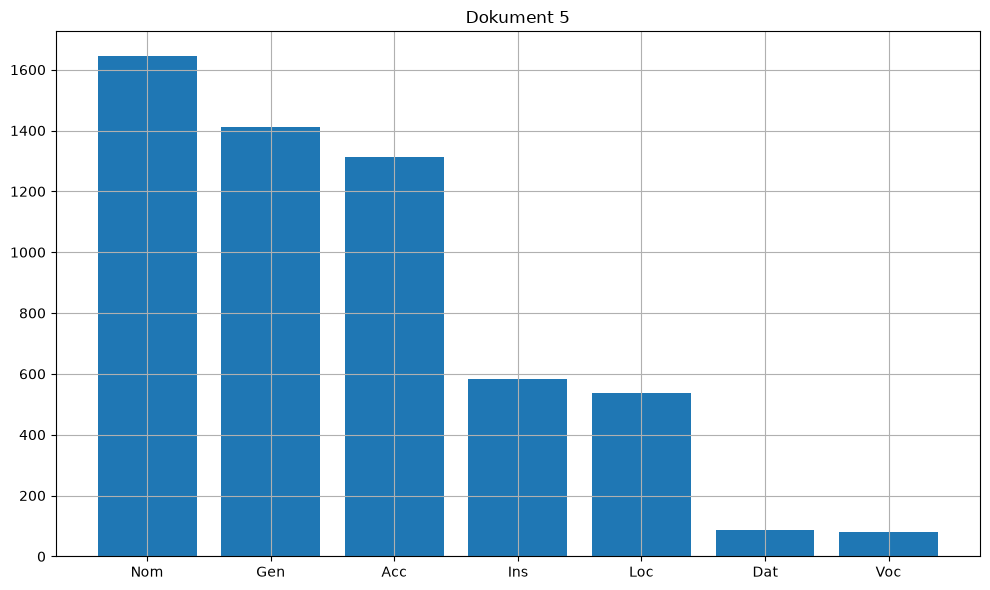

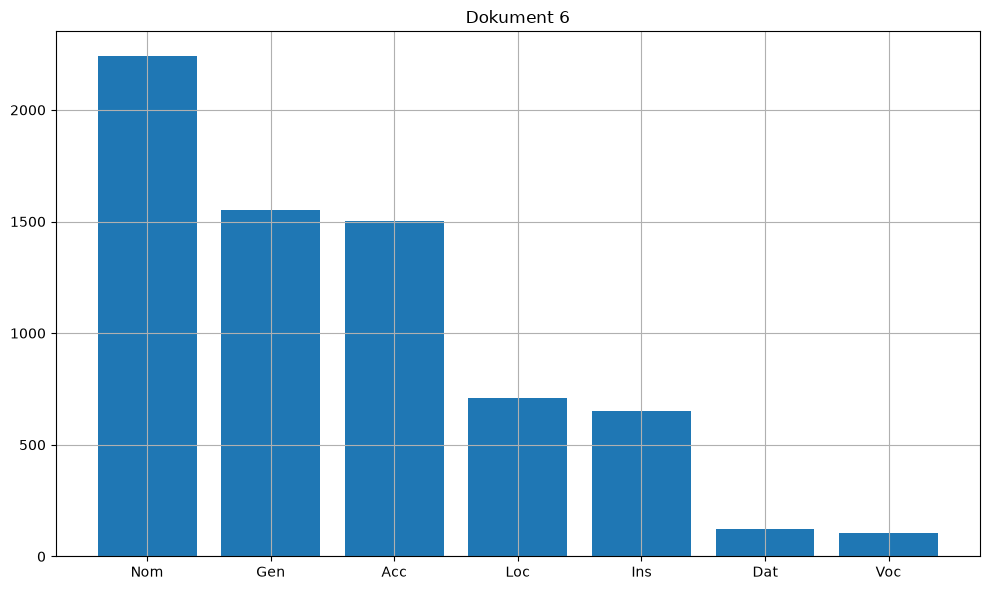

In [19]:
for i, book in enumerate(processed_books):
    cases = []
    for token in book:
        if token.pos_ == "NOUN":
            case = token.morph.get("Case")
            if case:
                cases.append(case[0])

    case_counts = Counter(cases)
    case_counts = dict(case_counts.most_common())

    plt.figure(figsize=(10, 6))
    plt.bar(case_counts.keys(),case_counts.values())
    plt.title(f'Dokument {i}')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

3. Na podstawie korpusu zbudowanego   z 5 dowolnych książek ściągniętych ze strony Wolne Lektury wyznaczyć i zwizualizować częstość występowania rzeczowników sprowadzonych do form podstawowych.

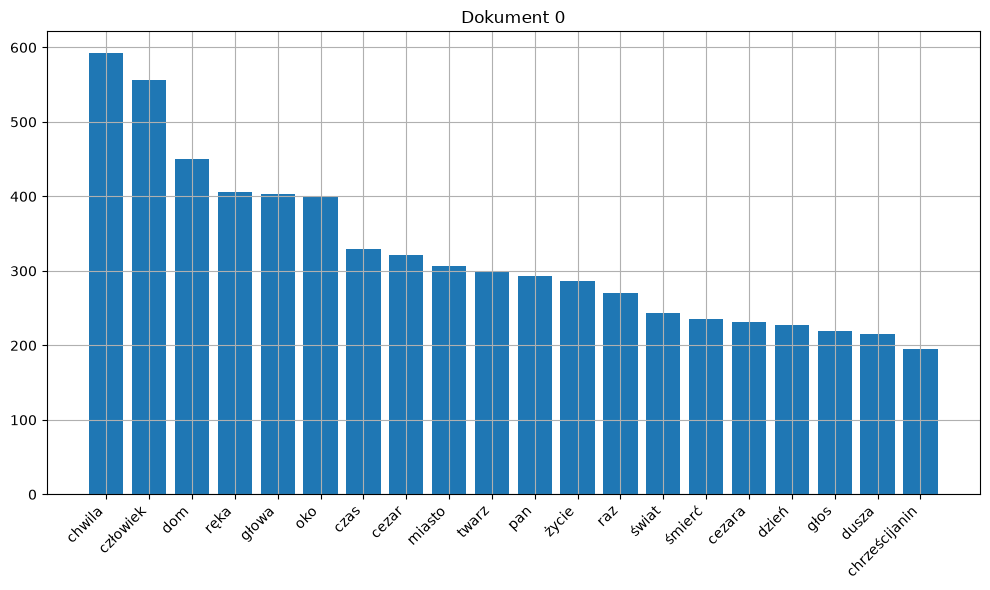

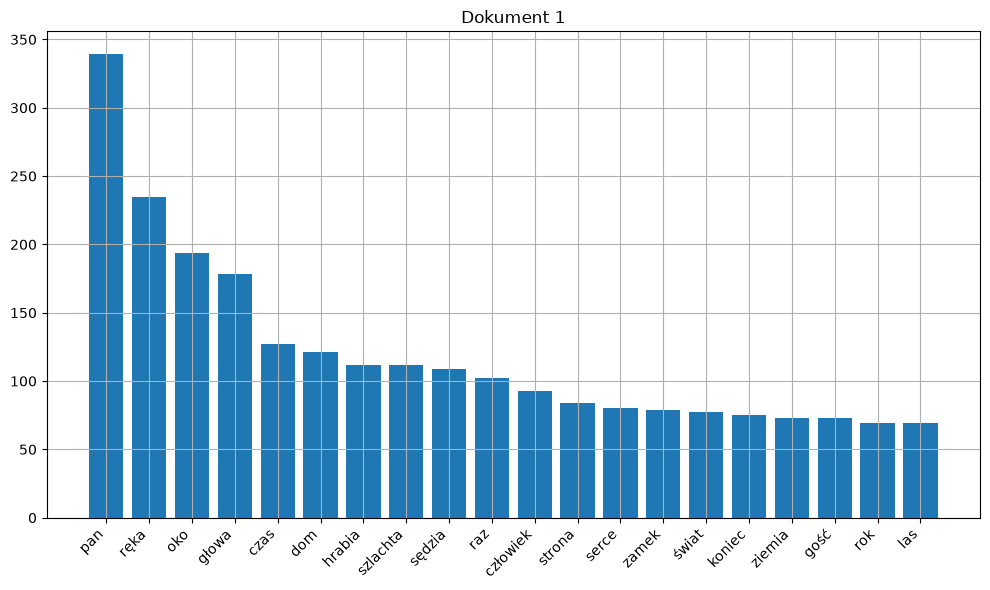

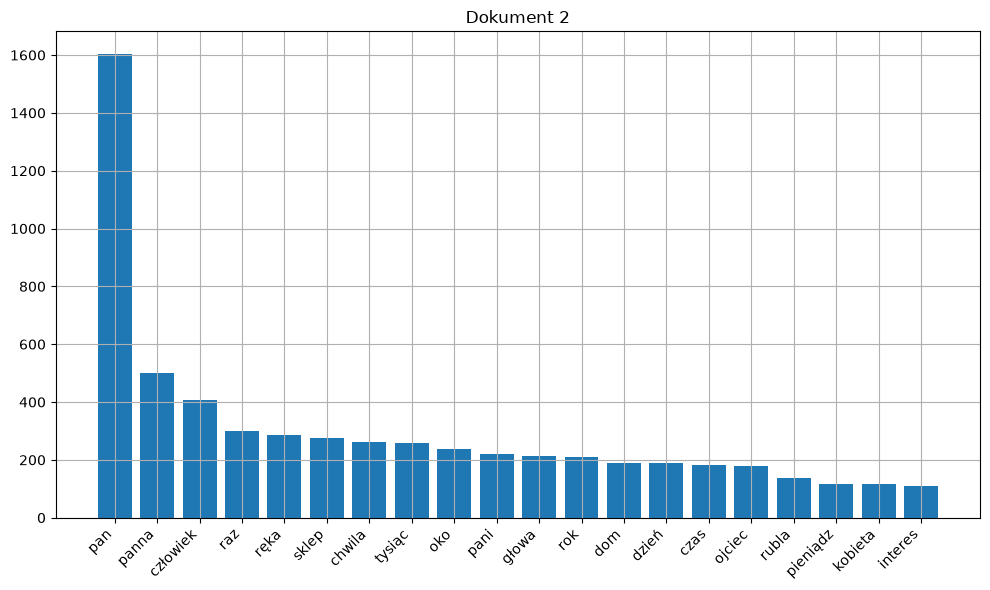

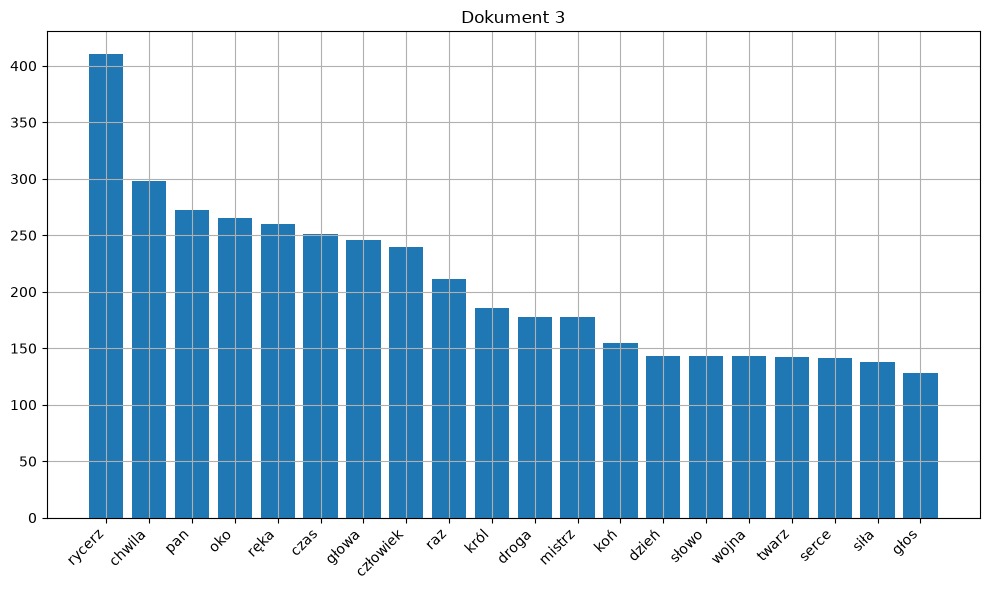

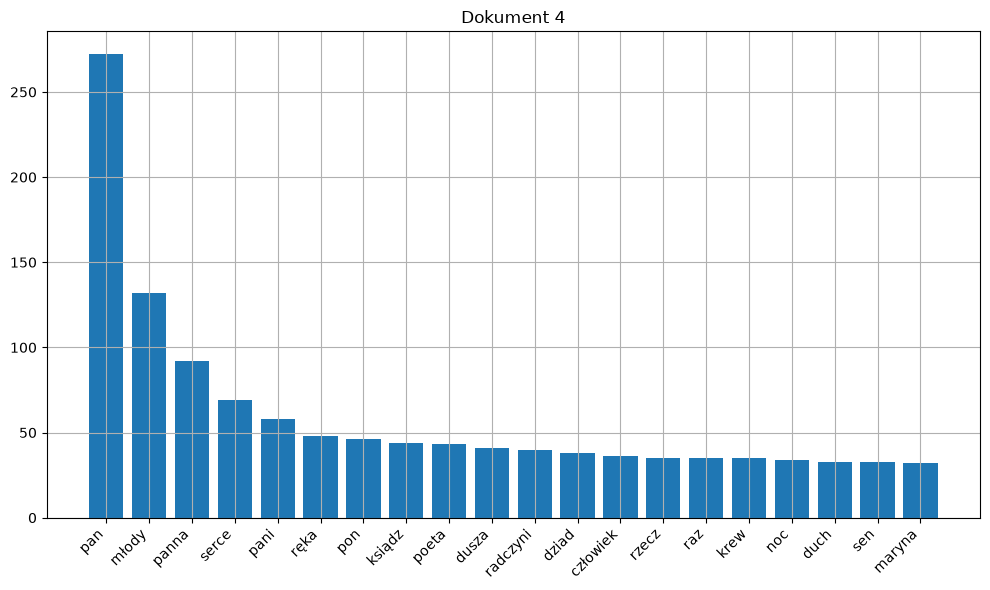

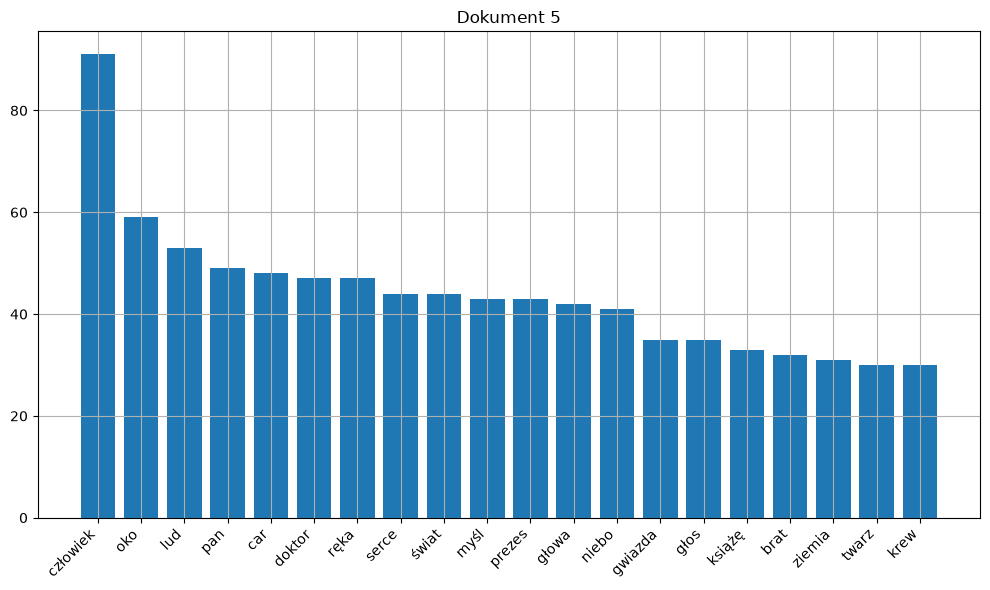

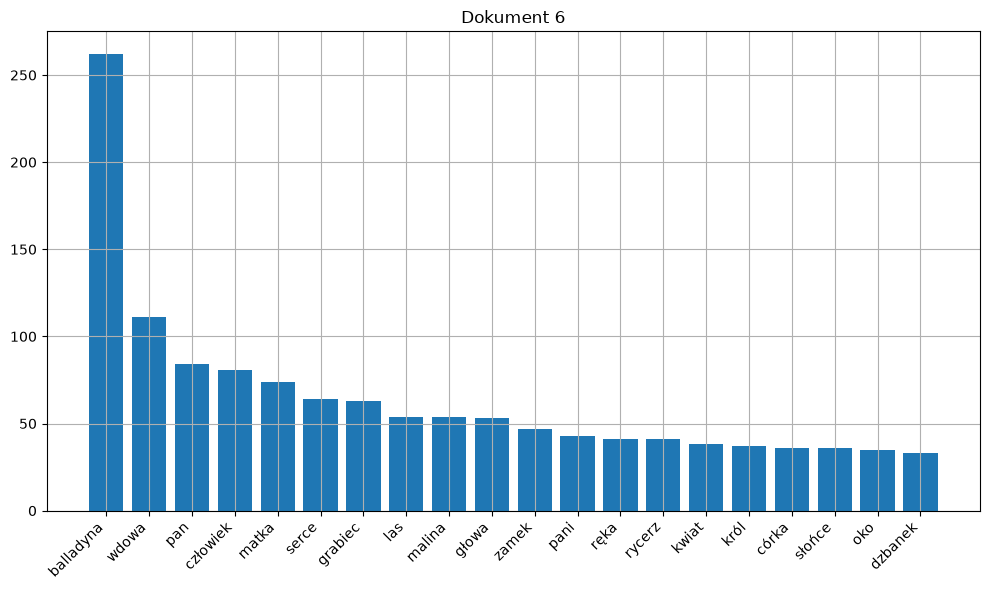

In [20]:
lemats=[]
for i, book in enumerate(processed_books):
    nouns=[token.lemma_.lower() for token in book
           if token.pos_=="NOUN" and token.is_alpha
           ]

    nouns_counts = Counter(nouns)
    lemats.append(nouns_counts)
    nouns_counts = dict(nouns_counts.most_common(20))

    plt.figure(figsize=(10, 6))
    plt.bar(nouns_counts.keys(),nouns_counts.values())
    plt.title(f'Dokument {i}')
    plt.grid(True)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

4.  Na podstawie częstości wyznaczonych powyżej  zbudować macierz tfidf, wyłącznie w oparciu o rzeczowniki w formie podstawowej i każdą pozycję zwizualizować w postaci chmury tagów (wordcloud).

                   a        aa    abdank   abdanka     abder      aber  \
Dokument 0  0.000000  0.001115  0.000000  0.000000  0.001115  0.000000   
Dokument 1  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
Dokument 2  0.002149  0.000000  0.000000  0.000000  0.000000  0.002149   
Dokument 3  0.000000  0.000000  0.001746  0.001746  0.000000  0.000000   
Dokument 4  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   

            absolucja      acan  ach      acte  ...      żółć   żądania  \
Dokument 0   0.000000  0.000000  0.0  0.000000  ...  0.000000  0.000000   
Dokument 1   0.002755  0.000000  0.0  0.000000  ...  0.002287  0.000000   
Dokument 2   0.000000  0.001784  0.0  0.001074  ...  0.000000  0.001074   
Dokument 3   0.000000  0.000000  0.0  0.000000  ...  0.000000  0.000000   
Dokument 4   0.000000  0.000000  0.0  0.000000  ...  0.000000  0.000000   

             żądanie     żądać      żądz     żądza  żądła     żądło    żęciem  \
Dokument 0  0.003164  0

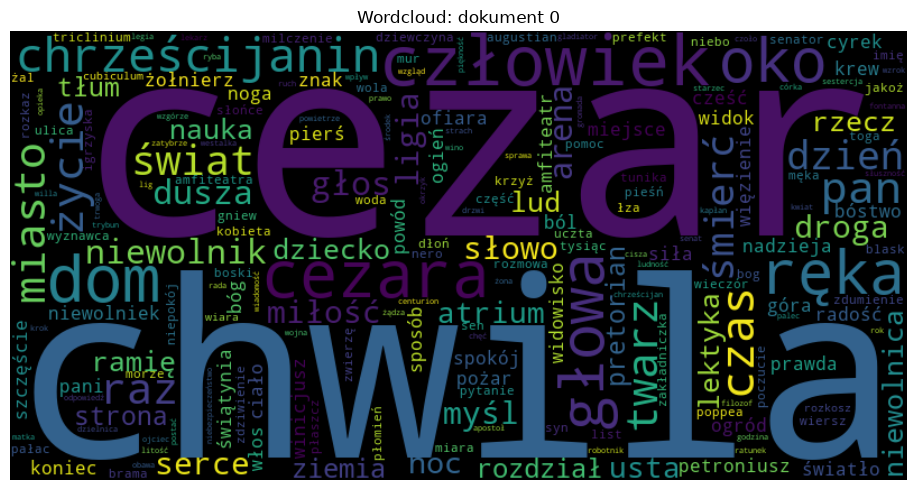

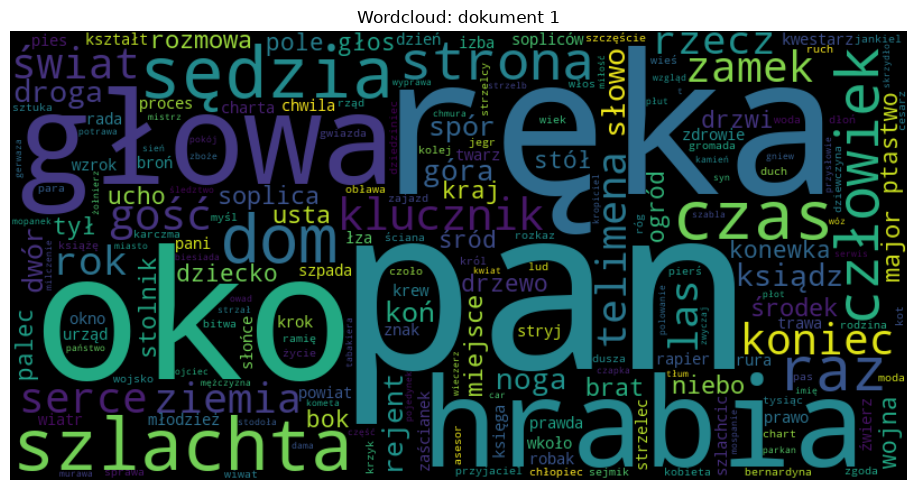

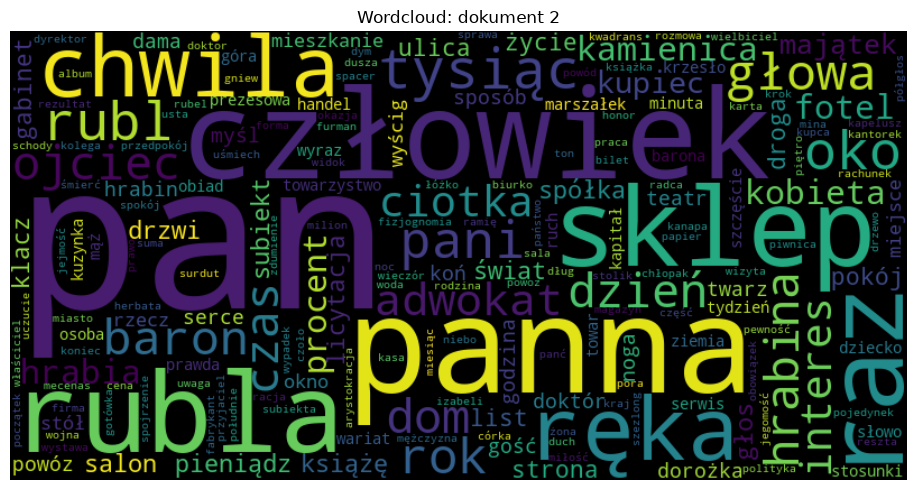

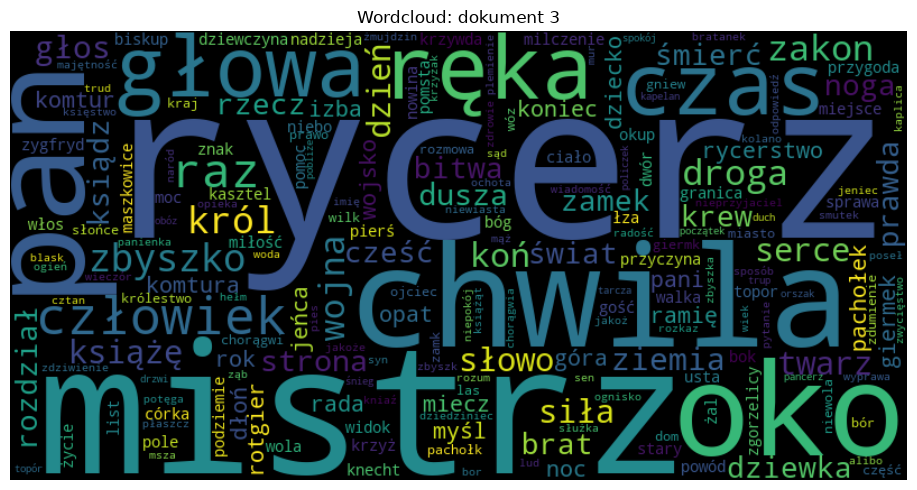

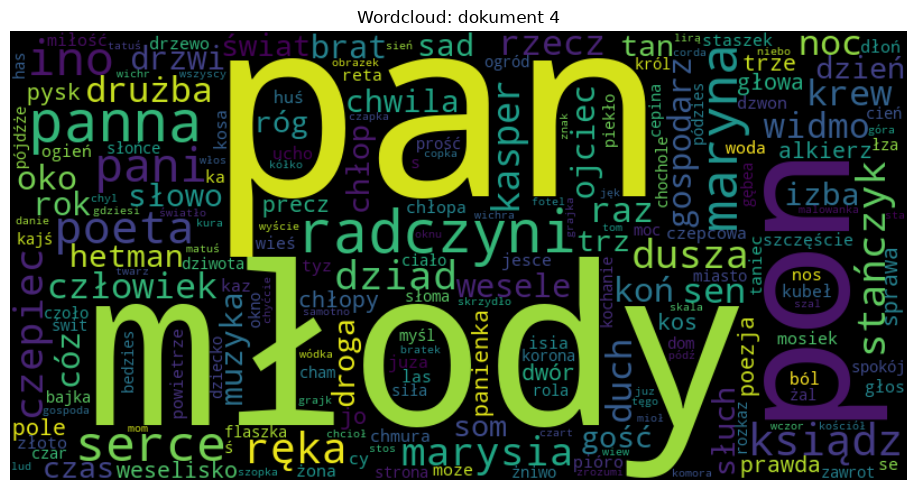

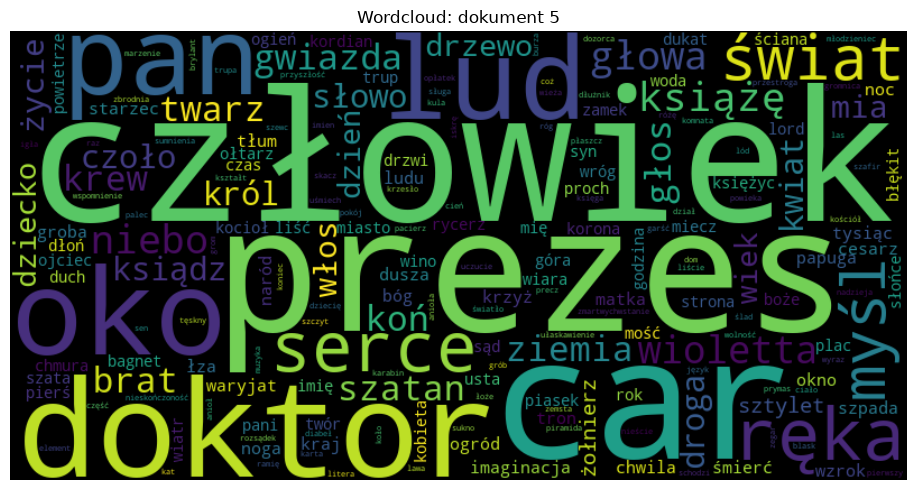

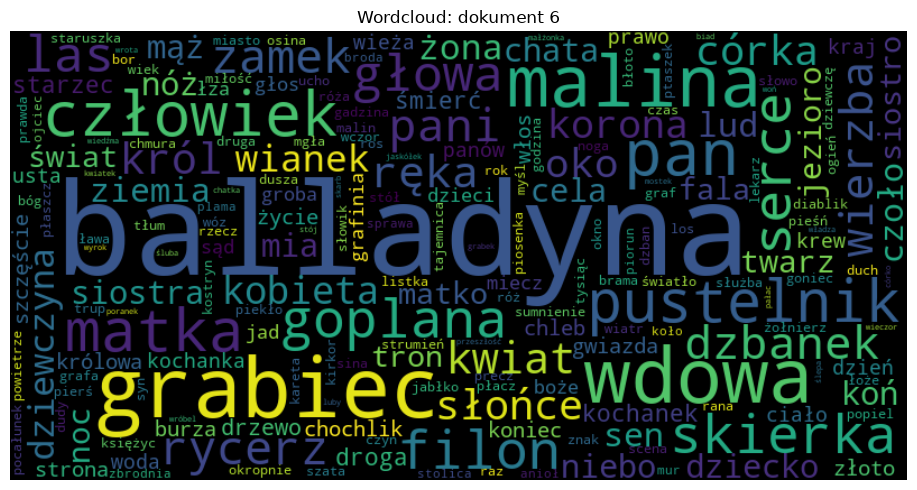

In [21]:
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.feature_extraction import DictVectorizer

vect=DictVectorizer(sparse=True)
X_counts=vect.fit_transform(lemats)

X_tfidf=TfidfTransformer().fit_transform(X_counts)
names=vect.get_feature_names_out()
titles = [f"Dokument {i}" for i in range(len(processed_books))]

import pandas as pd
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=names, index=titles)
print(df_tfidf.head())

from wordcloud import WordCloud

for i, (title,row) in enumerate(df_tfidf.iterrows()):
    tfifd_weights=row[row>0].to_dict()
    if tfifd_weights:
        wordcloud=WordCloud(
            width=800,
            height=400,
            colormap='viridis'
        ).generate_from_frequencies(tfifd_weights)

        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f'Wordcloud: dokument {i}')
        plt.tight_layout()
        plt.show()

5. Podać kilka przykładów  niejednoznaczności znaczeniowej  występującej w tekstach oraz przyjęty sposób ich rozwiązania

In [25]:
from collections import defaultdict

for book in processed_books[2:3]:
    lemma_pos_map=defaultdict(dict)
    for token in book:
        if token.is_alpha:
            lemma=token.lemma_.lower()
            tag=token.pos_
            if tag not in lemma_pos_map[lemma]:
                lemma_pos_map[lemma][tag]=token.sent.text.strip()


    ambiguous_words = {
        lemma: pos_dict
        for lemma,pos_dict in lemma_pos_map.items() if len(pos_dict)>1
    }

    for lemma, pos_dict in list(ambiguous_words.items())[10:20]:
        print(f" - '{lemma}': ")
        for tag,sentence in pos_dict.items():
            print(f"\t-{tag} : {sentence}")
        print()




 - 'zajmować': 
	-VERB : W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J.
	-ADJ : mówił — o wy, moi koledzy uniwersyteccy i syberyjscy, czy któryś z was wyobrażał sobie mnie zajmującego się podobnymi kwestiami?…”

 - 'nowy': 
	-ADJ : W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J.
	-NOUN : Trzej zaś nowi subiekci: galanteryjny, metalowy i gumowy, znowu tylko z sobą się wdają, są sztywni i pochmurni.

 - 'kupiec': 
	-NOUN : W początkach roku 1878, kiedy świat polityczny zajmował się pokojem 

Przykłady z lalki:
- 'gorąco':
	- Przysłówek : W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J.
	- Rzeczownik : — Miałem mały atak z gorąca i irytacji…
 - 'galanteryjny':
	- Przymiotnik : W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J.
	- WYkrzyknienie : Ale on był tylko kupcem, w dodatku — galanteryjnym!…

Jeśli dobrze rozumiem polecenie, typy zdań klasyfikowane są wykorzystując szerszy kontekst, tj. otoczenie analizowanego słowa. Same słowo zamek nie pozwala określic o chodzi, ale jezeli pod do np. CNN przekażemy również sąsiadów i dla takiej kombinacji obliczymy osadzenie, otrzymamy totalnie co innego dla tego samego słowa jakim jest przykładowy zamek.

6. W wybranej lekturze znaleźć 5  rzeczowników występujących w formie podmiotów oraz pokazać z jakimi czasownikami się łączą  w związku podmiotu z orzeczeniem.

In [32]:
subject_verb_pairs = defaultdict(set)
example_sentences = {}
book =  nlp(corpus[2])
for token in book:
    #Noun rzeczownik
    #PROPN reczwonik wlasny
    #nsubj podmiot
    #nsubjs pomniot w stornie biernej
    #verb czaoswinik
    #aux pomoniczy czasownik
    if token.pos_ in ["NOUN","PROPN"] and token.dep_ in ["nsubj", "nsubj:pass"]:
        head=token.head
        if head.pos_ in ["VERB","AUX"]:
            noun_lemma = token.lemma_.lower()
            verb_lemma = head.lemma_.lower()
            subject_verb_pairs[noun_lemma].add(verb_lemma)
            if  (noun_lemma,verb_lemma) not in example_sentences:
                example_sentences[(noun_lemma,verb_lemma)]=token.sent.text.strip()

top_5_subjects = sorted(subject_verb_pairs.keys(), key=lambda k: len(subject_verb_pairs[k]), reverse=True)[:5]

for noun in top_5_subjects:
    verbs=subject_verb_pairs[noun]
    print(f'podmiot: {noun}')
    print(f'czasowniki: {verbs}')

    print("Zdania:")
    print(list(verbs)[0])
    print(example_sentences[(noun,list(verbs)[0])])
    print(list(verbs)[1])
    print(example_sentences[(noun,list(verbs)[1])])
    print()

podmiot: pan
czasowniki: {'sądzić', 'pojmuje', 'tłoczyć', 'wysiąść', 'objaśnić', 'słyszeć', 'zachodzić', 'poprawić', 'upoważnić', 'winien', 'odzyskać', 'oddychać', 'uciekać', 'wymykać', 'strzelać', 'powiedzieć', 'pokiwać', 'dojrzać', 'wyobrazi', 'poczuć', 'przechadzać', 'podstawić', 'pochwycić', 'słyszyć', 'ożenić', 'posiadać', 'trzymać', 'podarować', 'osądzić', 'uspakajać', 'tworzyć', 'dawać', 'odkryć', 'myli', 'wyznać', 'dałbym', 'można', 'śmieć', 'gniewać', 'pracować', 'imponujeć', 'spoglądać', 'poznawać', 'zawołać', 'pojmować', 'ukłonić', 'słuchać', 'otworzyć', 'postarać', 'napisać', 'przyjść', 'staniesz', 'wyobraźyć', 'ukazać', 'dopomóc', 'zważać', 'potrzebujesz', 'musisz', 'zdać', 'obsypywać', 'wymyśleć', 'znajdziesz', 'zbladć być', 'móc by', 'drwić', 'ulżyć by', 'przekładać', 'znałeś', 'przepłacić', 'zakopować', 'przystępować', 'wygadować', 'westchnąć', 'dodawać', 'zauważyć', 'opowiadać', 'rzec', 'kazać być', 'powinien być', 'wziąć', 'pofatygować', 'bydło', 'myślisz', 'uspokoić'